In [44]:
# %pip install nflreadpy *UNCOMMENT/RUN ONLY ONCE TO INSTALL ON YOUR MACHINE* 
# %pip install adjustText *UNCOMMENT/RUN ONLY ONCE TO INSTALL ON YOUR MACHINE* 

import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 1. Load play-by-play data into memory
pbp_raw = nfl.load_pbp([2023, 2024, 2025])
pbp = pbp_raw.to_pandas() if hasattr(pbp_raw, 'to_pandas') else pbp_raw.copy()

# Export original source dataset for safe-keeping (no need to uncomment this)
# pbp.to_csv("play_by_play_2023_2025.csv", index=False)

In [45]:
# 2. Execute brief data cleaning (limits rows to runs & passes, eliminates 2-pt conversions with missing "down", forces numerics)
keep_cols = [
    'game_id', 'play_id', 'season', 'week', 'desc', 'play_type',
    'down', 'ydstogo', 'yardline_100', 'goal_to_go',
    'shotgun', 'no_huddle', 'score_differential',
    'game_seconds_remaining', 'half_seconds_remaining',
    'posteam_timeouts_remaining', 'defteam_timeouts_remaining',
    'posteam_type'
]

plays_df = pbp.loc[
    (pbp['play_type'].isin(['pass', 'run'])) &
    (pbp['down'].notna()),
    keep_cols
].copy()

plays_df['is_pass'] = (plays_df['play_type'] == 'pass').astype(int)
plays_df['posteam_type'] = (plays_df['posteam_type'] == 'home').astype(int)
plays_df

,game_id,play_id,season,week,desc,play_type,down,ydstogo,yardline_100,goal_to_go,shotgun,no_huddle,score_differential,game_seconds_remaining,half_seconds_remaining,posteam_timeouts_remaining,defteam_timeouts_remaining,posteam_type,is_pass
2,2023_01_ARI_WAS,55.0,2023,1,(15:00) (Shotgun) 8-B.Robinson right tackle to...,run,1.0,10.0,75.0,0.0,1.0,0.0,0.0,3600.0,1800.0,3.0,3.0,1,0
3,2023_01_ARI_WAS,77.0,2023,1,(14:30) (Shotgun) 14-S.Howell pass short right...,pass,2.0,7.0,72.0,0.0,1.0,0.0,0.0,3570.0,1770.0,3.0,3.0,1,1
4,2023_01_ARI_WAS,102.0,2023,1,(13:55) 23-C.Rodriguez left guard to WAS 36 fo...,run,3.0,1.0,66.0,0.0,0.0,0.0,0.0,3535.0,1735.0,3.0,3.0,1,0
5,2023_01_ARI_WAS,124.0,2023,1,(13:16) (Shotgun) 14-S.Howell pass incomplete ...,pass,1.0,10.0,64.0,0.0,1.0,0.0,0.0,3496.0,1696.0,3.0,3.0,1,1
6,2023_01_ARI_WAS,147.0,2023,1,(13:12) 14-S.Howell pass short middle to 1-J.D...,pass,2.0,10.0,64.0,0.0,0.0,0.0,0.0,3492.0,1692.0,3.0,3.0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147920,2025_22_SEA_NE,4459.0,2025,22,"(1:30) (No Huddle, Shotgun) 10-D.Maye pass sho...",pass,2.0,4.0,88.0,0.0,1.0,1.0,-16.0,90.0,90.0,0.0,0.0,1,1
147921,2025_22_SEA_NE,4484.0,2025,22,"(1:12) (No Huddle, Shotgun) 10-D.Maye pass sho...",pass,1.0,10.0,83.0,0.0,1.0,1.0,-16.0,72.0,72.0,0.0,0.0,1,1
147924,2025_22_SEA_NE,4578.0,2025,22,"(:39) (No Huddle, Shotgun) 10-D.Maye pass shor...",pass,1.0,10.0,62.0,0.0,1.0,1.0,-16.0,39.0,39.0,0.0,0.0,1,1
147925,2025_22_SEA_NE,4603.0,2025,22,"(:20) (No Huddle, Shotgun) 10-D.Maye pass inco...",pass,2.0,1.0,53.0,0.0,1.0,1.0,-16.0,20.0,20.0,0.0,0.0,1,1


In [46]:
# 3. Generate ground-truth binary target (y) and one-hot encoded feature matrix (x)
feature_cols = [
    'down', 'ydstogo', 'yardline_100', 'goal_to_go',
    'shotgun', 'no_huddle', 'score_differential',
    'game_seconds_remaining', 'half_seconds_remaining',
    'posteam_timeouts_remaining', 'defteam_timeouts_remaining',
    'posteam_type'
]

x = plays_df[feature_cols]
y = plays_df['is_pass']

In [47]:
# 4. Split rows into 80% training and 20% testing
x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=31337
)
print(f'{len(x_train)} training plays, {len(x_test)} testing plays')

83902 training plays, 20976 testing plays


,Maximum Tree Depth,Accuracy on Training Data,Accuracy on Testing Data
0,1,0.700293,0.697178
1,2,0.700293,0.697178
2,3,0.700293,0.697178
3,4,0.703249,0.699895
4,5,0.703630,0.700038
5,6,0.710400,0.707523
6,7,0.712617,0.706903
7,8,0.719625,0.709859
8,9,0.724369,0.711003
9,10,0.729768,0.709477


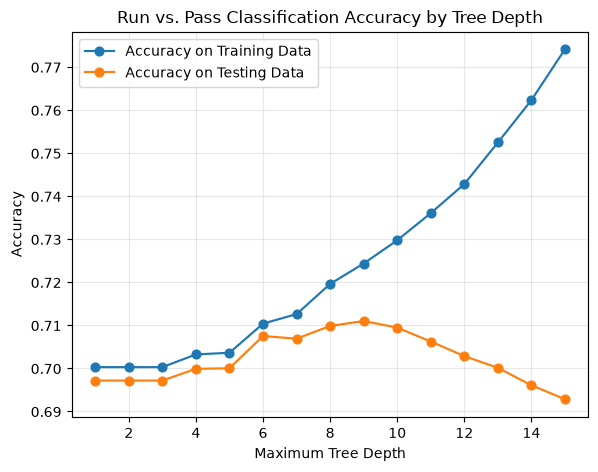

In [48]:
# 5. Test Decision Trees with max_depth 1 through 15
tree_rows = []
for depth in range(1, 16):
    model = DecisionTreeClassifier(max_depth=depth, random_state=31337)
    model.fit(x_train, y_train)
    
    tree_rows.append({
        "Maximum Tree Depth": depth,
        "Accuracy on Training Data": accuracy_score(y_train, model.predict(x_train)),
        "Accuracy on Testing Data": accuracy_score(y_test, model.predict(x_test)),
    })

tree_df = pd.DataFrame(tree_rows)
display(tree_df)

tree_df.plot(x="Maximum Tree Depth", y=["Accuracy on Training Data", "Accuracy on Testing Data"], marker="o", ylabel="Accuracy")
plt.title("Run vs. Pass Classification Accuracy by Tree Depth")
plt.grid(True, alpha=0.3)
plt.show()

In [49]:
# 6. Final Model Decision
final_model = DecisionTreeClassifier(max_depth=6, random_state=31337)
final_model.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",31337
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples 

In [50]:
# 7. Generate predictions on the unseen plays (testing data)
output_df = plays_df.loc[x_test.index].copy()
output_df["predicted_is_pass"] = final_model.predict(x_test)
output_df["predicted_play_type"] = output_df["predicted_is_pass"].map({1: "pass", 0: "run"})
output_df["correct_prediction"] = (output_df["is_pass"] == output_df["predicted_is_pass"])
output_df

,game_id,play_id,season,week,desc,play_type,down,ydstogo,yardline_100,goal_to_go,...,score_differential,game_seconds_remaining,half_seconds_remaining,posteam_timeouts_remaining,defteam_timeouts_remaining,posteam_type,is_pass,predicted_is_pass,predicted_play_type,correct_prediction
145231,2025_18_SEA_SF,2282.0,2025,18,(5:22) (Shotgun) 13-B.Purdy pass short left to...,pass,3.0,2.0,83.0,0.0,...,-7.0,1222.0,1222.0,3.0,3.0,1,1,1,pass,True
65078,2024_06_SF_SEA,1496.0,2024,6,(6:23) 31-I.Guerendo right end to SEA 40 for 1...,run,1.0,10.0,41.0,0.0,...,13.0,2183.0,383.0,3.0,3.0,0,0,0,run,True
137700,2025_16_ATL_ARI,3610.0,2025,16,(9:33) (Shotgun) 25-T.Allgeier right tackle to...,run,1.0,15.0,60.0,0.0,...,10.0,573.0,573.0,3.0,3.0,0,0,1,pass,False
99063,2024_22_KC_PHI,2035.0,2024,22,(1:27) (Shotgun) 15-P.Mahomes pass incomplete ...,pass,1.0,20.0,80.0,0.0,...,-24.0,1887.0,87.0,1.0,2.0,0,1,1,pass,True
106441,2025_03_LA_PHI,1079.0,2025,3,(14:14) 23-K.Williams right guard to LA 47 for...,run,1.0,10.0,53.0,0.0,...,3.0,2654.0,854.0,3.0,3.0,0,0,0,run,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
52768,2024_02_CHI_HOU,667.0,2024,2,(2:21) (Shotgun) 7-C.Stroud pass short right t...,pass,3.0,7.0,56.0,0.0,...,0.0,2841.0,1041.0,3.0,3.0,1,1,1,pass,True
72567,2024_09_LV_CIN,706.0,2024,9,(2:27) (Shotgun) 9-J.Burrow pass short left to...,pass,2.0,7.0,7.0,1.0,...,-7.0,2847.0,1047.0,3.0,3.0,1,1,1,pass,True
138790,2025_16_LA_SEA,1424.0,2025,16,(7:53) (Shotgun) 23-K.Williams up the middle t...,run,3.0,2.0,41.0,0.0,...,-1.0,2273.0,473.0,3.0,3.0,0,0,1,pass,False
41343,2023_16_NO_LA,208.0,2023,16,(11:20) (Shotgun) 4-D.Carr pass incomplete sho...,pass,2.0,7.0,31.0,0.0,...,0.0,3380.0,1580.0,3.0,3.0,0,1,1,pass,True


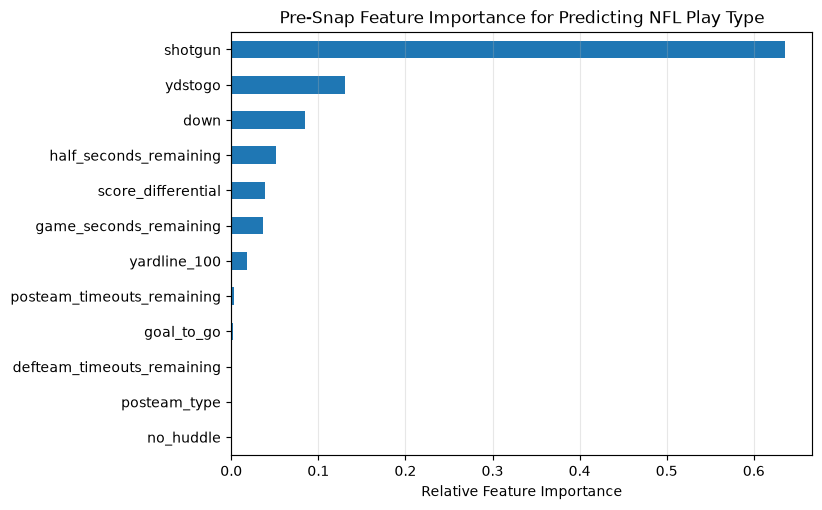

In [51]:
# 8. Plot importances of each feature
feat_imp = pd.Series(final_model.feature_importances_, index=feature_cols).sort_values()

feat_imp.plot(kind="barh", figsize=(8, 5), color="#1f77b4")
plt.title("Pre-Snap Feature Importance for Predicting NFL Play Type")
plt.xlabel("Relative Feature Importance")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()